# Projeto – Detecção de spam em mensagens: classificação com regressão logística

PAM0466 – Sistemas Inteligentes

**Alunos:**

- ANA KELLY NOBRE COSTA
- PEDRO ARTUR PESSOA ALVES
- TALES IGOR ALMEIDA SILVA

Mensagens de spam (propaganda indesejada, golpes e promoções falsas) incomodam o usuário e podem ser fraudulentas. Um filtro automático pode estimar, a partir de características da mensagem, a probabilidade de ela ser spam e decidir se deve ser bloqueada. É nesse contexto que o aprendizado de máquina pode contribuir: um modelo de classificação treinado com mensagens já rotuladas aprende quais características estão associadas ao spam e aplica esse aprendizado a mensagens novas.

**Objetivo:** Detecção de spam em mensagens: classificação com regressão logística. Neste projeto, construímos um modelo utilizando regressão logística para prever se uma mensagem SMS é spam ou mensagem desejada (ham).

O projeto utiliza o dataset *SMS Spam Collection* (UCI Machine Learning Repository, disponível em https://archive.ics.uci.edu/dataset/228/sms+spam+collection), com 5.574 mensagens SMS em inglês, cada uma rotulada como `ham` ou `spam`. Referência: Almeida, T. & Hidalgo, J. (2011). SMS Spam Collection [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CC84. O arquivo `SMSSpamCollection` tem uma mensagem por linha: o rótulo, uma tabulação e o texto. Os rótulos são os do dataset original: **`spam`** (mensagem indesejada) e **`ham`** (mensagem desejada, ou seja, *não spam*).

**Variável dependente (saída):** `y`, que indica se a mensagem é spam. O rótulo original (`ham` ou `spam`) é binarizado para 0 (`ham`, mensagem desejada, não spam) e 1 (`spam`) antes do treinamento.

**Variáveis independentes (entradas):** características numéricas extraídas do texto de cada mensagem, pois a regressão logística exige números:
- `n_caracteres` — tamanho da mensagem;
- `n_digitos` — quantidade de dígitos (telefones, códigos e valores);
- `n_maiusculas` — quantidade de letras maiúsculas;
- `n_exclamacoes` — quantidade de pontos de exclamação;
- `tem_moeda` — a mensagem contém símbolo de moeda (1 = sim, 0 = não);
- `kw_<palavra>` — presença de cada uma das 30 palavras-chave de spam escolhidas no conjunto de treino (1 = a mensagem contém a palavra, 0 = não contém).

## Pré-processamento dos dados

Etapas do pré-processamento, na ordem em que são feitas abaixo: (1) carregar os dados e dar nome às colunas; (2) tratar valores ausentes; (3) tratar dados redundantes (duplicatas); (4) análise exploratória; (5) binarizar a variável alvo; (6) dividir em treino e teste; (7) extrair as características numéricas do texto; (8) padronizar as variáveis independentes. A divisão vem antes de escolher as palavras-chave e de padronizar, para que as palavras-chave, a média e o desvio padrão sejam calculados só no treino, sem vazamento de informação do teste.

### Carregamento dos dados

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# sep='\t': campos separados por tabulação; header=None: o arquivo não tem cabeçalho;
# quoting=3: aspas fazem parte do texto das mensagens e não devem ser interpretadas
df = pd.read_csv('SMSSpamCollection', sep='\t', header=None, names=['rotulo', 'texto'], quoting=3)

print('Formato (mensagens, colunas):', df.shape)
df.head()

Formato (mensagens, colunas): (5574, 2)


,rotulo,texto
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Distribuição das classes

In [2]:
# quantidade e percentual de cada classe
print(df['rotulo'].value_counts())
print((df['rotulo'].value_counts(normalize=True) * 100).round(2))

rotulo
ham     4827
spam     747
Name: count, dtype: int64
rotulo
ham     86.6
spam    13.4
Name: proportion, dtype: float64


O conjunto é **desbalanceado**: há muito mais *ham* que *spam*. Nesse caso a acurácia não é confiável (paradoxo da acurácia), por isso a avaliação usa também precisão, revocação, F1 e AUC.

### Valores ausentes

In [3]:
# quantidade de valores ausentes (NaN) em cada coluna e de mensagens vazias
print(df.isnull().sum())
print('Mensagens vazias:', (df['texto'].str.strip() == '').sum())

rotulo    0
texto     0
dtype: int64
Mensagens vazias: 0


Não há valores ausentes nem mensagens vazias: o rótulo e o texto estão preenchidos em todas as linhas. Por isso não é necessário nenhum tratamento (imputação) nesta etapa.

### Dados redundantes (duplicatas)

In [4]:
# mensagens repetidas (mesmo rótulo e mesmo texto)
print('Mensagens duplicadas:', df.duplicated().sum())

# remove as duplicatas ANTES de dividir em treino e teste, para que a mesma mensagem não apareça nos dois
df = df.drop_duplicates().reset_index(drop=True)
print('Formato após remover duplicatas:', df.shape)
print(df['rotulo'].value_counts())

Mensagens duplicadas: 403
Formato após remover duplicatas: (5171, 2)
rotulo
ham     4518
spam     653
Name: count, dtype: int64


### Análise exploratória

         count   mean   std   min    25%    50%    75%    max
rotulo                                                       
ham     4518.0   70.9  56.6   2.0   34.0   53.0   91.0  910.0
spam     653.0  137.7  29.8  13.0  132.0  148.0  157.0  223.0


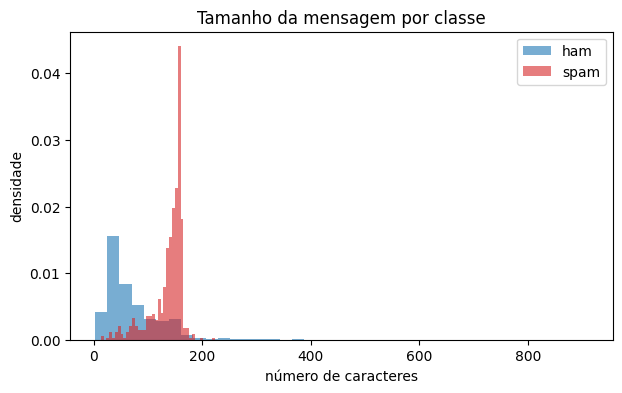

In [5]:
# tamanho de cada mensagem (número de caracteres) e estatísticas por classe
df['tamanho'] = df['texto'].str.len()
print(df.groupby('rotulo')['tamanho'].describe().round(1))

# histograma do tamanho por classe
plt.figure(figsize=(7, 4))
for r, cor in [('ham', 'tab:blue'), ('spam', 'tab:red')]:
    plt.hist(df.loc[df['rotulo'] == r, 'tamanho'], bins=40, alpha=0.6, label=r, color=cor, density=True)
plt.title('Tamanho da mensagem por classe'); plt.xlabel('número de caracteres'); plt.ylabel('densidade')
plt.legend(); plt.show()

### Binarização da variável alvo

O rótulo original é texto (`ham` ou `spam`). Ele é transformado em número: **spam = 1** (classe positiva) e **ham = 0**.

In [6]:
# binarização: spam vira 1 e ham vira 0
print('Distribuição original (rótulo):')
print(df['rotulo'].value_counts())

df['y'] = (df['rotulo'] == 'spam').astype(int)

print()
print('Distribuição após a binarização:')
print(df['y'].value_counts().sort_index())

Distribuição original (rótulo):
rotulo
ham     4518
spam     653
Name: count, dtype: int64

Distribuição após a binarização:
y
0    4518
1     653
Name: count, dtype: int64


### Divisão treino/teste

A divisão é feita **antes** de qualquer aprendizado a partir dos dados, para que o teste simule mensagens nunca vistas.

In [7]:
from sklearn.model_selection import train_test_split

X = df['texto']               # texto bruto da mensagem (as características numéricas são extraídas na etapa seguinte)
y = df['y']                  # variável dependente: 0 = ham, 1 = spam

# 70% treino / 30% teste; stratify=y mantém a mesma proporção de spam nos dois conjuntos;
# random_state=42 fixa o sorteio (resultado reproduzível)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

print(f"Treino: {X_train.shape[0]} amostras | % de spam: {y_train.mean() * 100:.2f}")
print(f"Teste:  {X_test.shape[0]} amostras | % de spam: {y_test.mean() * 100:.2f}")

Treino: 3619 amostras | % de spam: 12.63
Teste:  1552 amostras | % de spam: 12.63


### Extração das características numéricas

A regressão logística calcula $z = \theta_0 + \theta_1 x_1 + \dots + \theta_p x_p$ e, por isso, exige **características numéricas**. Cada mensagem será descrita por:

- **características numéricas**: número de caracteres, de dígitos, de letras maiúsculas e de pontos de exclamação;
- **características binárias (0/1)**: presença de símbolo de moeda e presença de cada **palavra-chave** (transformação de simbólico para numérico: a mensagem contém a palavra = 1, não contém = 0).

As palavras-chave são escolhidas **só com o conjunto de treino**: entre as palavras que aparecem em pelo menos 10 mensagens de treino, ficam as que têm taxa de spam de pelo menos 80%, e usamos as 30 mais frequentes em spam.

In [8]:
# palavras (só letras, minúsculas) de cada mensagem do TREINO; set() conta cada palavra uma vez por mensagem
palavras = X_train.str.lower().str.findall(r'[a-z]+').apply(lambda lista: list(set(lista)))

# uma linha por (mensagem, palavra), com o rótulo da mensagem
pw = pd.DataFrame({'palavra': palavras, 'y': y_train}).explode('palavra')

# para cada palavra: em quantas mensagens aparece (count), quantas são spam (sum) e a taxa de spam
estat = pw.groupby('palavra')['y'].agg(['count', 'sum'])
estat['taxa_spam'] = estat['sum'] / estat['count']

selecao = estat[(estat['count'] >= 10) & (estat['taxa_spam'] >= 0.80)].sort_values('sum', ascending=False).head(30)
palavras_chave = list(selecao.index)

print('Palavras-chave escolhidas:', palavras_chave)
print(selecao.round(3).head(10))

Palavras-chave escolhidas: ['p', 'txt', 'mobile', 'www', 'claim', 'prize', 'win', 'cash', 'com', 'urgent', 'uk', 'box', 'contact', 'nokia', 'service', 'guaranteed', 'co', 'ppm', 'draw', 'per', 'tone', 'cs', 'video', 'shows', 'line', 'po', 'code', 'awarded', 'ringtone', 'wk']
         count  sum  taxa_spam
palavra                       
p          105   98      0.933
txt         96   87      0.906
mobile      83   72      0.867
www         64   63      0.984
claim       61   61      1.000
prize       53   53      1.000
win         46   42      0.913
cash        51   42      0.824
com         49   41      0.837
urgent      43   39      0.907


In [9]:
def extrair_caracteristicas(textos):
    # transforma cada mensagem em um vetor numérico (uma linha por mensagem)
    minusc = textos.str.lower()
    F = pd.DataFrame({
        'n_caracteres':  textos.str.len(),
        'n_digitos':     textos.str.count(r'\d'),
        'n_maiusculas':  textos.str.count(r'[A-Z]'),
        'n_exclamacoes': textos.str.count('!'),
        'tem_moeda':     minusc.str.contains(r'£|\$').astype(int),
    })
    for p in palavras_chave:
        F['kw_' + p] = minusc.str.contains(r'\b' + p + r'\b', regex=True).astype(int)
    return F

# as mesmas palavras-chave (aprendidas no treino) são aplicadas ao treino e ao teste
F_train = extrair_caracteristicas(X_train)
F_test = extrair_caracteristicas(X_test)

print('Características por mensagem:', F_train.shape[1])
F_train.head()

Características por mensagem: 35


,n_caracteres,n_digitos,n_maiusculas,n_exclamacoes,tem_moeda,kw_p,kw_txt,kw_mobile,kw_www,kw_claim,...,kw_tone,kw_cs,kw_video,kw_shows,kw_line,kw_po,kw_code,kw_awarded,kw_ringtone,kw_wk
1679,39,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2839,59,0,3,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4389,9,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
610,59,0,2,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2457,28,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [10]:
# variável dependente (saída) e variáveis independentes (entradas)
tipo = ['numérica' if c.startswith('n_') else 'binária' for c in F_train.columns]
variaveis = pd.DataFrame({'variável': F_train.columns, 'tipo': tipo})

print('Variável dependente (y): 0 = ham, 1 = spam')
print('Quantidade de variáveis independentes (X):', F_train.shape[1])
print(variaveis['tipo'].value_counts())
print()
print(variaveis.to_string(index=False))

Variável dependente (y): 0 = ham, 1 = spam
Quantidade de variáveis independentes (X): 35
tipo
binária     31
numérica     4
Name: count, dtype: int64

     variável     tipo
 n_caracteres numérica
    n_digitos numérica
 n_maiusculas numérica
n_exclamacoes numérica
    tem_moeda  binária
         kw_p  binária
       kw_txt  binária
    kw_mobile  binária
       kw_www  binária
     kw_claim  binária
     kw_prize  binária
       kw_win  binária
      kw_cash  binária
       kw_com  binária
    kw_urgent  binária
        kw_uk  binária
       kw_box  binária
   kw_contact  binária
     kw_nokia  binária
   kw_service  binária
kw_guaranteed  binária
        kw_co  binária
       kw_ppm  binária
      kw_draw  binária
       kw_per  binária
      kw_tone  binária
        kw_cs  binária
     kw_video  binária
     kw_shows  binária
      kw_line  binária
        kw_po  binária
      kw_code  binária
   kw_awarded  binária
  kw_ringtone  binária
        kw_wk  binária


### Padronização

As características têm escalas muito diferentes. Vamos utilizar a padronização (z-score): $x' = \dfrac{x - \mu}{\sigma}$, com média 0 e desvio padrão 1. A média e o desvio são calculados **apenas no conjunto de treinamento** (`fit`) e depois aplicados ao conjunto de teste (`transform`); fazer o `fit` com o conjunto completo contamina a validação.

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(F_train)   # fit + transform no TREINO: aprende média e desvio e aplica
X_test_sc = scaler.transform(F_test)         # apenas transform no TESTE: usa a média e o desvio do treino

print('Treino - média: %.3f | desvio: %.3f' % (X_train_sc.mean(), X_train_sc.std()))
print('Teste  - média: %.3f | desvio: %.3f' % (X_test_sc.mean(), X_test_sc.std()))

Treino - média: -0.000 | desvio: 1.000
Teste  - média: -0.007 | desvio: 0.975


### Verificação da separabilidade linear

A regressão logística separa as classes por uma fronteira linear (o ponto em que $z = 0$). Por isso verificamos se as classes são linearmente separáveis nas características extraídas. Se fossem, um modelo linear, praticamente sem regularização, classificaria todo o conjunto de treino corretamente. Se não forem, restam erros que uma fronteira linear não consegue eliminar.

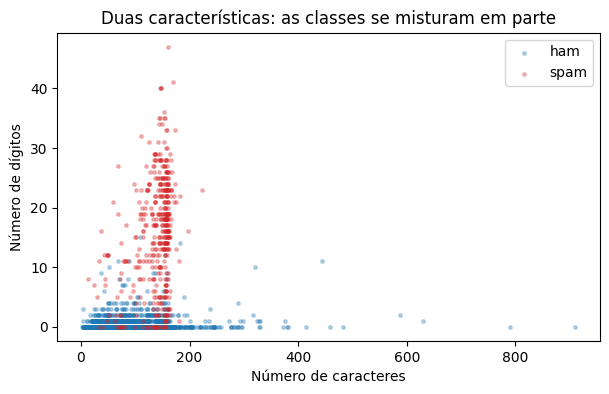

In [12]:
# gráfico de duas características (tamanho x dígitos), uma cor por classe
plt.figure(figsize=(7, 4))
for r, cor in [(0, 'tab:blue'), (1, 'tab:red')]:
    sel = (y_train == r).to_numpy()
    plt.scatter(F_train['n_caracteres'][sel], F_train['n_digitos'][sel], s=6, alpha=0.3, color=cor,
                label='spam' if r == 1 else 'ham')
plt.xlabel('Número de caracteres')
plt.ylabel('Número de dígitos')
plt.title('Duas características: as classes se misturam em parte')
plt.legend()
plt.show()

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

# modelo linear praticamente sem regularização (C muito grande): quantos erros restam NO TREINO?
model_sep = LogisticRegression(C=1e6, max_iter=100000, random_state=42)
model_sep.fit(X_train_sc, y_train)
pred_sep = model_sep.predict(X_train_sc)

cm_sep = confusion_matrix(y_train, pred_sep)
print(pd.DataFrame(cm_sep, index=['real ham', 'real spam'], columns=['previsto ham', 'previsto spam']))
erros = cm_sep[0, 1] + cm_sep[1, 0]
print(f'Erros no treino: {erros} de {len(y_train)} ({100 * erros / len(y_train):.2f}%)')
print(f'Acertos no treino: {100 * (1 - erros / len(y_train)):.2f}%')

           previsto ham  previsto spam
real ham           3147             15
real spam            40            417
Erros no treino: 55 de 3619 (1.52%)
Acertos no treino: 98.48%


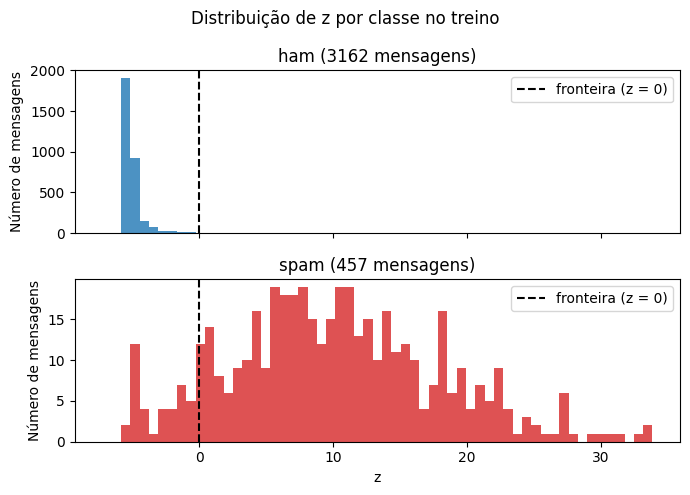

Spams do lado do ham (z < 0): 40
Hams do lado do spam (z > 0): 15


In [14]:
# valor de z = theta0 + theta1*x1 + ... para cada mensagem de treino; a fronteira linear é z = 0
z = model_sep.decision_function(X_train_sc)
z_ham = z[(y_train == 0).to_numpy()]
z_spam = z[(y_train == 1).to_numpy()]

# um painel por classe (cada um com a sua escala), para o spam não ficar escondido pela quantidade de ham
bins = np.linspace(z.min(), z.max(), 60)
fig, eixos = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
for ax, valores, cor, nome in [(eixos[0], z_ham, 'tab:blue', 'ham'), (eixos[1], z_spam, 'tab:red', 'spam')]:
    ax.hist(valores, bins=bins, color=cor, alpha=0.8)
    ax.axvline(0, color='k', linestyle='--', label='fronteira (z = 0)')
    ax.set_ylabel('Número de mensagens')
    ax.set_title(f'{nome} ({len(valores)} mensagens)')
    ax.legend(loc='upper right')
eixos[1].set_xlabel('z')
fig.suptitle('Distribuição de z por classe no treino')
plt.tight_layout()
plt.show()

print(f'Spams do lado do ham (z < 0): {(z_spam < 0).sum()}')
print(f'Hams do lado do spam (z > 0): {(z_ham > 0).sum()}')

As classes **não são perfeitamente separáveis** de forma linear: mesmo com regularização desprezível, o modelo linear ainda erra algumas mensagens do próprio treino, e esses erros são mensagens que ficam do outro lado da fronteira. A separação é, porém, **quase linear**: a grande maioria das mensagens fica do lado correto, com a maior parte do ham bem à esquerda da fronteira e a maior parte do spam à direita. Por isso a regressão logística é adequada, e os erros que restam (principalmente spams que passam) são o limite de uma fronteira linear com estas características.

## Treinamento de um modelo de LogisticRegression (scikit-learn) com os dados de treino, usando max_iter=1000 e random_state=42, e número de iterações necessárias para a convergência

### Ajuste dos parâmetros utilizando o gradiente descendente

Para visualizar a curva logística, vamos treinar um modelo sem a `sklearn`, com **uma única característica**: o número de dígitos da mensagem (spams costumam trazer telefones, códigos e valores).

Função logística: $h_\theta(z) = \dfrac{1}{1 + e^{-z}}$, com $z = \theta_0 + \theta_1 x_1 + \dots + \theta_p x_p$ e $\hat{p} = h_\theta\left(\mathbf{\Phi}^T\mathbf{x}\right)$.

Função de custo (Log Loss ou entropia cruzada binária):

$$ J(\mathbf{\Phi}) = -\frac{1}{N}\sum_{i=0}^{N-1} \left[ y^{(i)} \log \hat{p}^{(i)} + \left(1 - y^{(i)}\right) \log\left(1 - \hat{p}^{(i)}\right) \right] $$

Regra de atualização do gradiente descendente, com taxa de aprendizagem $\eta$:

$$ \theta_j := \theta_j - \eta \frac{1}{N}\sum_{i=0}^{N-1} \left[ h_\theta\left(\mathbf{\Phi}^T\mathbf{x}^{(i)}\right) - y^{(i)} \right] x_j^{(i)} $$

In [15]:
# característica única: número de dígitos (padronizada com a média e o desvio do treino)
digitos = F_train['n_digitos'].to_numpy(dtype=float)
mu, sigma = digitos.mean(), digitos.std()
X_raw = (digitos - mu) / sigma
y_gd = y_train.to_numpy()

print('Média de dígitos - ham :', digitos[y_gd == 0].mean().round(2))
print('Média de dígitos - spam:', digitos[y_gd == 1].mean().round(2))

Média de dígitos - ham : 0.31
Média de dígitos - spam: 15.78


In [16]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def compute_cost(X, y, theta):
    N = len(y)
    z = np.dot(X, theta)
    h = sigmoid(z)

    # evita log(0) adicionando um valor minúsculo (epsilon)
    epsilon = 1e-15
    cost = -(1/N) * np.sum(y * np.log(h + epsilon) + (1 - y) * np.log(1 - h + epsilon))
    return cost

def gradient_descent(X, y, theta, eta, iterations):
    N, p = X.shape
    cost_history = []

    for i in range(iterations):
        z = np.dot(X, theta)
        h = sigmoid(z)
        error = h - y
        gradient = (1/N) * np.dot(X.T, error)     # derivada do custo em relação a theta
        theta = theta - eta * gradient            # passo contra o gradiente
        cost_history.append(compute_cost(X, y, theta))

        if i % 100 == 0:
            print(f"Iteração {i}: Custo {cost_history[-1]:.4f}")

    return theta, cost_history

Para o algoritmo funcionar, o vetor $\mathbf{x}$ deve possuir uma coluna apenas com valores `1` (termo $\theta_0$):

In [17]:
X = np.column_stack((np.ones(X_raw.shape[0]), X_raw))

eta = 0.1
iterations = 1000

theta = np.zeros(X.shape[1])                    # inicialização com zeros
final_theta, history = gradient_descent(X, y_gd, theta, eta, iterations)
final_theta

Iteração 0: Custo 0.6718
Iteração 100: Custo 0.1839
Iteração 200: Custo 0.1401
Iteração 300: Custo 0.1258
Iteração 400: Custo 0.1190
Iteração 500: Custo 0.1151
Iteração 600: Custo 0.1126
Iteração 700: Custo 0.1108
Iteração 800: Custo 0.1096
Iteração 900: Custo 0.1087


array([-2.58354335,  3.04766864])

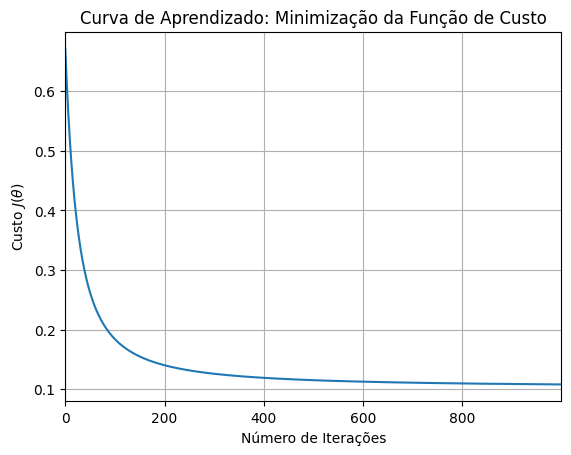

In [18]:
# curva de aprendizado: relação entre o custo e o número de iterações
plt.plot(history)
plt.title('Curva de Aprendizado: Minimização da Função de Custo')
plt.xlabel('Número de Iterações')
plt.ylabel('Custo $J(\\theta)$')
plt.xlim([0, iterations-1])
plt.grid()
plt.show()

In [19]:
def p_est(x):
    # probabilidade de spam para uma mensagem com x dígitos
    return sigmoid(final_theta[0] + final_theta[1] * (x - mu) / sigma)

for x in [0, 10, 25]:
    print(f"{x:2d} dígitos -> Probabilidade de spam = {p_est(x):.4f}")

 0 dígitos -> Probabilidade de spam = 0.0241
10 dígitos -> Probabilidade de spam = 0.7767
25 dígitos -> Probabilidade de spam = 0.9998


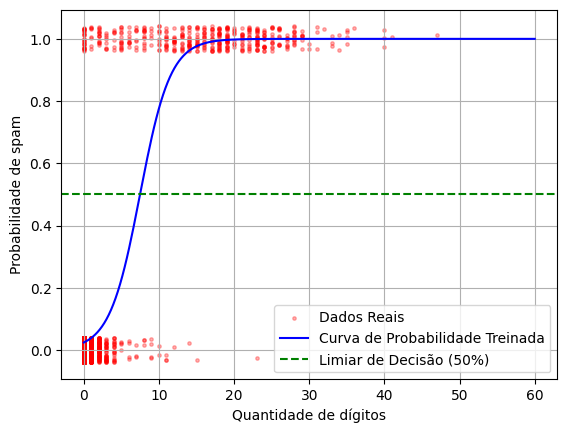

In [20]:
# curva de probabilidade treinada sobre os dados de treinamento
rng = np.random.RandomState(0)
X_plot = np.linspace(0, 60, 200)

plt.scatter(digitos, y_gd + rng.uniform(-0.04, 0.04, len(y_gd)), s=6, alpha=0.3, color='red', label='Dados Reais')
plt.plot(X_plot, p_est(X_plot), color='blue', label='Curva de Probabilidade Treinada')
plt.axhline(0.5, color='green', linestyle='--', label='Limiar de Decisão (50%)')
plt.xlabel('Quantidade de dígitos')
plt.ylabel('Probabilidade de spam')
plt.legend()
plt.grid()
plt.show()

Com uma única característica, o gradiente descendente reduz o custo a cada iteração (curva de aprendizado) e ajusta uma curva logística em que a probabilidade de spam cresce com o número de dígitos: mensagens sem dígitos têm probabilidade baixa e mensagens com muitos dígitos têm probabilidade próxima de 1, valores impressos acima. É um modelo simples, que usa só uma característica; a seguir o modelo usa todas.

### Treinamento com a `sklearn`

Agora vamos usar o modelo `LogisticRegression` e o método `fit()` com **todas** as características (palavras-chave, tamanho, dígitos, etc.), já padronizadas. Não é necessário adicionar a coluna de `1`, pois a `sklearn` já faz isso internamente.

In [21]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,     # máximo de iterações
    random_state=42,
)

model.fit(X_train_sc, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [22]:
# parâmetros do modelo treinado: theta_0 (intercept_) e theta_1, ..., theta_p (coef_)
t0 = model.intercept_
tvalues = model.coef_[0]

print(f"Iterações até a convergência (n_iter_): {int(model.n_iter_[0])}")
print(f"θ0 = {t0}")
print(f"Quantidade de coeficientes θ1, ..., θp = {len(tvalues)}")

# coeficientes de maior valor absoluto: positivo aumenta a chance de spam, negativo diminui
coef = pd.Series(tvalues, index=F_train.columns)
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(10).round(4))

Iterações até a convergência (n_iter_): 18
θ0 = [-3.11233666]
Quantidade de coeficientes θ1, ..., θp = 35
n_digitos      3.0245
kw_ringtone    0.6530
kw_co          0.5796
kw_service     0.5183
kw_txt         0.5128
kw_mobile      0.4867
kw_win         0.4531
kw_nokia       0.4118
kw_com         0.3658
kw_video       0.3653
dtype: float64


Com os parâmetros salvos no vetor $\mathbf{\Phi}$, a probabilidade de a mensagem ser spam é $\hat{p} = \dfrac{1}{1 + e^{-\mathbf{\Phi}^T\mathbf{x}}}$, e a decisão usa o limiar de 0,5:
* Se $\hat{p} < 0,5$, a mensagem é classificada como **ham** (desejada);
* Se $\hat{p} \geq 0,5$, a mensagem é classificada como **spam**.

In [23]:
theta = np.concatenate((t0, tvalues))

def model_predict(theta, x):
    z = np.dot(x, theta)
    p = sigmoid(z)
    status = 'ham' if p < 0.5 else 'spam'
    return status, p

# duas mensagens do conjunto de teste
for i in [7, 14]:
    X_example = np.concatenate(([1], X_test_sc[i]))
    status, p = model_predict(theta, X_example)
    print(f"Mensagem: {X_test.iloc[i]}")
    print(f"Real = {'spam' if y_test.iloc[i] == 1 else 'ham'} | Previsão = {status} | Probabilidade (spam) = {p*100:.2f}%\n")

Mensagem: Mum, i've sent you many many messages since i got here. I just want to know that you are actually getting them. Do enjoy the rest of your day.
Real = ham | Previsão = ham | Probabilidade (spam) = 0.73%

Mensagem: Thats cool princess! I will cover your face in hot sticky cum :)
Real = ham | Previsão = ham | Probabilidade (spam) = 0.77%



In [24]:
# previsão da classe e probabilidade de spam para todo o conjunto de teste
y_pred = model.predict(X_test_sc)
y_prob = model.predict_proba(X_test_sc)[:, 1]

O modelo foi treinado com a `sklearn` e o atributo `n_iter_` mostra que o algoritmo convergiu com um número de iterações muito abaixo do limite `max_iter`. Coeficientes positivos aumentam a chance de spam e negativos diminuem; entre as características de maior valor absoluto, o número de dígitos tem o maior efeito, seguido de palavras-chave típicas de spam. A função `model_predict` repete à mão o cálculo da `sklearn` (sigmoide de $\mathbf{\Phi}^T\mathbf{x}$ e limiar de 0,5) e classifica as duas mensagens do teste mostradas, com a probabilidade de spam de cada uma.

## Avaliação do modelo com os dados de teste: matriz de confusão, acurácia, precisão, revocação, F1-score e curva ROC com valor de AUC

### Matriz de confusão e métricas

A matriz de confusão relaciona os rótulos reais com os rótulos previstos (classe positiva = **spam**):

- **VP** (verdadeiro positivo): era spam, previu spam;
- **VN** (verdadeiro negativo): era ham, previu ham;
- **FP** (falso positivo): era ham, previu spam: erro tipo I (alarme falso);
- **FN** (falso negativo): era spam, previu ham: erro tipo II.

$$ Acurácia = \frac{VP+VN}{VP+VN+FP+FN} \qquad Precisão = \frac{VP}{VP+FP} \qquad Revocação = \frac{VP}{VP+FN} \qquad F1 = 2 \cdot \frac{Precisão \cdot Revocação}{Precisão + Revocação} $$

- **Precisão:** dos que eu marquei como spam, quantos realmente eram? Penaliza FP;
- **Revocação (recall):** dos que realmente eram spam, quantos eu encontrei? Penaliza FN;
- **F1:** média harmônica de precisão e revocação.

No filtro de spam, um FP joga uma mensagem legítima no lixo: prioriza-se a **precisão**.

           previsto ham  previsto spam
real ham           1352              4
real spam            23            173
VN = 1352 | FP = 4 | FN = 23 | VP = 173


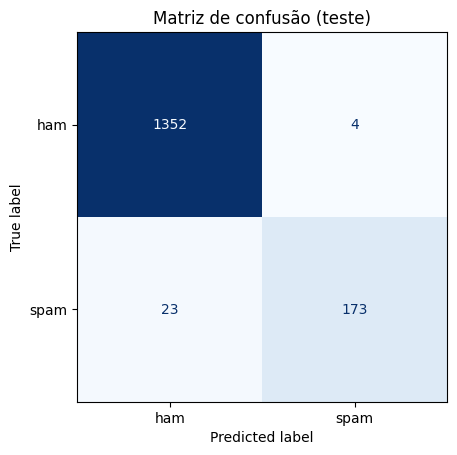

In [25]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve, accuracy_score,
    precision_score, recall_score, f1_score
)

# matriz de confusão: linhas = real, colunas = previsto
cm = confusion_matrix(y_test, y_pred)
vn, fp, fn, vp = cm.ravel()
print(pd.DataFrame(cm, index=['real ham', 'real spam'], columns=['previsto ham', 'previsto spam']))
print(f'VN = {vn} | FP = {fp} | FN = {fn} | VP = {vp}')

# matriz de confusão desenhada (linhas = real, colunas = previsto)
ConfusionMatrixDisplay(cm, display_labels=['ham', 'spam']).plot(cmap='Blues', colorbar=False)
plt.grid(False)
plt.title('Matriz de confusão (teste)')
plt.show()

In [26]:
# leitura da matriz de confusão (os números vêm do código)
print(f'* {vn} mensagens desejadas (ham) foram corretamente liberadas;')
print(f'* {fp} mensagens desejadas (ham) foram classificadas como spam (falsos positivos: alarmes falsos);')
print(f'* {fn} spams foram classificados como ham (falsos negativos: spams que passaram);')
print(f'* {vp} spams foram corretamente detectados.')
print()
print(f'Das {vp + fp} mensagens que o modelo bloqueou, {vp} eram spam e {fp} eram mensagens desejadas.')
print(f'Dos {vp + fn} spams existentes no teste, o modelo detectou {vp} e deixou passar {fn}.')

* 1352 mensagens desejadas (ham) foram corretamente liberadas;
* 4 mensagens desejadas (ham) foram classificadas como spam (falsos positivos: alarmes falsos);
* 23 spams foram classificados como ham (falsos negativos: spams que passaram);
* 173 spams foram corretamente detectados.

Das 177 mensagens que o modelo bloqueou, 173 eram spam e 4 eram mensagens desejadas.
Dos 196 spams existentes no teste, o modelo detectou 173 e deixou passar 23.


In [27]:
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisão: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred):.4f}")

Acurácia: 0.9826
Precisão: 0.9774
Recall: 0.8827
F1-Score: 0.9276


### Curva ROC e AUC

A curva ROC é o gráfico da taxa de verdadeiros positivos (TPR) versus a taxa de falsos positivos (FPR), variando o limiar de decisão: $TPR = \dfrac{VP}{VP+FN}$ (= revocação) e $FPR = \dfrac{FP}{FP+VN}$. A AUC é a área sob a curva ROC ($0 \leq AUC \leq 1$): valores de 0,9 a 1,0 são considerados excelentes e 0,5 equivale a jogar uma moeda.

AUC-ROC:  0.9876


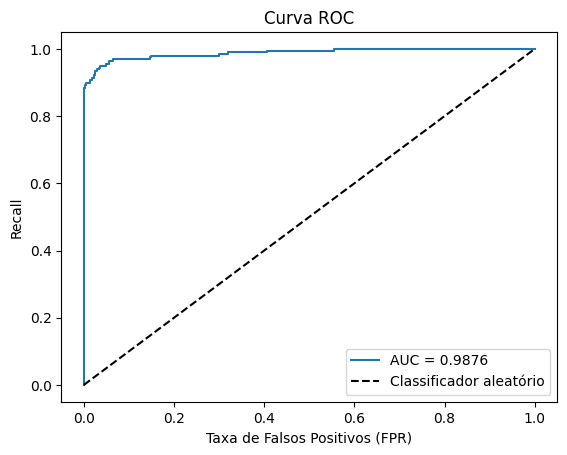

In [28]:
# curva ROC e AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

print(f"AUC-ROC:  {auc:.4f}")

plt.plot(fpr, tpr, label=f'AUC = {auc:.4f}')
plt.plot([0, 1], [0, 1], 'k--', label='Classificador aleatório')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Recall')
plt.title('Curva ROC')
plt.legend()
plt.show()

In [29]:
# resumo final de todas as métricas
resumo = pd.Series({'Acurácia': accuracy_score(y_test, y_pred), 'Precisão': precision_score(y_test, y_pred),
                    'Recall': recall_score(y_test, y_pred), 'F1-score': f1_score(y_test, y_pred), 'AUC': auc}, name='Teste')
print(resumo.round(4))

Acurácia    0.9826
Precisão    0.9774
Recall      0.8827
F1-score    0.9276
AUC         0.9876
Name: Teste, dtype: float64


### Limiar de decisão

A regra usada até aqui classifica como spam quando $\hat{p} \geq 0{,}5$. Esse limiar pode ser alterado: **diminuir** o limiar faz o modelo detectar mais spams (revocação maior) mas bloquear mais mensagens desejadas (mais falsos positivos); **aumentar** faz o contrário (precisão maior, mais spams passam). Para escolher o limiar sem usar o conjunto de teste, as probabilidades são obtidas por validação cruzada (5 folds) **no treino**.

In [30]:
from sklearn.model_selection import cross_val_predict

# probabilidade de spam de cada mensagem de treino, prevista por um modelo que não a viu (validação cruzada)
prob_cv = cross_val_predict(LogisticRegression(max_iter=1000, random_state=42), X_train_sc, y_train,
                            cv=5, method='predict_proba')[:, 1]

limiares = np.arange(0.1, 0.91, 0.1)
linhas = []
for t in limiares:
    pt = (prob_cv >= t).astype(int)
    linhas.append([round(t, 1), precision_score(y_train, pt), recall_score(y_train, pt), f1_score(y_train, pt)])
tab_cv = pd.DataFrame(linhas, columns=['limiar', 'precisão', 'revocação', 'F1']).set_index('limiar')
print('Validação cruzada no treino:')
print(tab_cv.round(4))

# limiar (passo 0,01) que maximiza o F1 na validação cruzada
grade = np.arange(0.05, 0.96, 0.01)
f1_grade = [f1_score(y_train, (prob_cv >= t).astype(int)) for t in grade]
limiar_cv = float(grade[int(np.argmax(f1_grade))])
print(f'\nLimiar com maior F1 na validação cruzada: {limiar_cv:.2f}')

Validação cruzada no treino:
        precisão  revocação      F1
limiar                             
0.1       0.8635     0.9409  0.9005
0.2       0.9077     0.9256  0.9166
0.3       0.9227     0.9147  0.9187
0.4       0.9412     0.9103  0.9255
0.5       0.9580     0.8993  0.9278
0.6       0.9641     0.8818  0.9211
0.7       0.9754     0.8687  0.9190
0.8       0.9821     0.8403  0.9057
0.9       0.9894     0.8184  0.8958

Limiar com maior F1 na validação cruzada: 0.50


         VP  FP  FN  precisão  revocação      F1
limiar                                          
0.1     178  25  18    0.8768     0.9082  0.8922
0.2     176  15  20    0.9215     0.8980  0.9096
0.3     176  10  20    0.9462     0.8980  0.9215
0.4     175   6  21    0.9669     0.8929  0.9284
0.5     173   4  23    0.9774     0.8827  0.9276
0.6     166   1  30    0.9940     0.8469  0.9146
0.7     163   1  33    0.9939     0.8316  0.9056
0.8     161   1  35    0.9938     0.8214  0.8994
0.9     157   1  39    0.9937     0.8010  0.8870


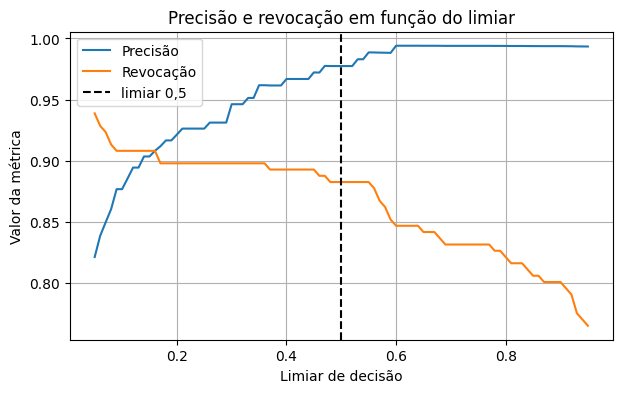

In [31]:
# efeito de cada limiar no conjunto de TESTE (probabilidades do modelo treinado com a sklearn)
linhas = []
for t in limiares:
    pe = (y_prob >= t).astype(int)
    vp_t = ((pe == 1) & (y_test == 1)).sum(); fp_t = ((pe == 1) & (y_test == 0)).sum()
    fn_t = ((pe == 0) & (y_test == 1)).sum()
    linhas.append([round(t, 1), vp_t, fp_t, fn_t, precision_score(y_test, pe), recall_score(y_test, pe), f1_score(y_test, pe)])
tab_te = pd.DataFrame(linhas, columns=['limiar', 'VP', 'FP', 'FN', 'precisão', 'revocação', 'F1']).set_index('limiar')
print(tab_te.round(4))

# precisão e revocação em função do limiar
grade_t = np.arange(0.05, 0.96, 0.01)
plt.figure(figsize=(7, 4))
plt.plot(grade_t, [precision_score(y_test, (y_prob >= t).astype(int)) for t in grade_t], label='Precisão')
plt.plot(grade_t, [recall_score(y_test, (y_prob >= t).astype(int)) for t in grade_t], label='Revocação')
plt.axvline(0.5, color='k', linestyle='--', label='limiar 0,5')
plt.xlabel('Limiar de decisão')
plt.ylabel('Valor da métrica')
plt.title('Precisão e revocação em função do limiar')
plt.legend()
plt.grid()
plt.show()

In [32]:
# leitura (os números vêm do código)
print(f'Limiar 0,5 : {tab_te.loc[0.5, "FP"]} falsos positivos e {tab_te.loc[0.5, "FN"]} falsos negativos.')
print(f'Limiar 0,3 : {tab_te.loc[0.3, "FP"]} falsos positivos e {tab_te.loc[0.3, "FN"]} falsos negativos (detecta mais spam, bloqueia mais ham).')
print(f'Limiar 0,7 : {tab_te.loc[0.7, "FP"]} falsos positivos e {tab_te.loc[0.7, "FN"]} falsos negativos (quase não bloqueia ham, mas deixa passar mais spam).')

Limiar 0,5 : 4 falsos positivos e 23 falsos negativos.
Limiar 0,3 : 10 falsos positivos e 20 falsos negativos (detecta mais spam, bloqueia mais ham).
Limiar 0,7 : 1 falsos positivos e 33 falsos negativos (quase não bloqueia ham, mas deixa passar mais spam).


O limiar de 0,5 é o que maximiza o F1 na validação cruzada, e variar o limiar em poucos centésimos ao redor dele muda pouco o resultado. Mudar o limiar não elimina os erros, apenas **troca um tipo de erro pelo outro**: num filtro de spam, em que bloquear uma mensagem desejada (falso positivo) é mais grave, limiares um pouco maiores reduzem os falsos positivos ao custo de mais spams que passam. Mantivemos 0,5 por ser a regra padrão e o melhor equilíbrio entre precisão e revocação.

O modelo foi avaliado no conjunto de teste, que não participou do treinamento. A matriz de confusão mostra quantas mensagens desejadas foram bloqueadas (FP) e quantos spams passaram (FN). Como as classes são desbalanceadas, a acurácia deve ser lida junto com a precisão, a revocação e o F1: a **precisão** indica a confiança no que é bloqueado, a **revocação** indica quantos spams são encontrados e o **F1** equilibra as duas. A AUC na faixa de 0,9 a 1,0 é considerada excelente: o modelo separa bem as duas classes em praticamente qualquer limiar.

## Aplicação de regularização (L1 e L2) e validação cruzada para escolher a melhor configuração do modelo, avaliada no conjunto de teste

### Regularização e validação cruzada

O overfitting ocorre quando o modelo "decora" os dados de treino e não generaliza. A regularização adiciona uma penalização à função de custo, baseada na magnitude dos pesos:

- Lasso (L1): $J_{reg}(\mathbf{\Phi}) = J(\mathbf{\Phi}) + \alpha \sum_{i=1}^{p} |\theta_i|$
- Ridge (L2): $J_{reg}(\mathbf{\Phi}) = J(\mathbf{\Phi}) + \dfrac{\alpha}{2} \sum_{i=1}^{p} \theta_i^2$

O parâmetro $\alpha$ controla a força da regularização: $\alpha$ muito alto causa underfitting e muito baixo não resolve o overfitting. A L1 tende a zerar coeficientes, enquanto a L2 apenas os reduz. Na `sklearn`, $C = 1/\alpha$, então valores altos de C indicam pouca regularização.

O valor adequado de $\alpha$ é estimado por **validação cruzada** (k-fold): o conjunto de treinamento é dividido em k partes e, a cada rodada, uma parte é usada para validar e as demais para treinar. O resultado é a média dos k escores e o desvio padrão indica a estabilidade. Usamos k = 5 e, como as classes são desbalanceadas, o escore é o **F1**.

In [33]:
configs = [
    {'l1_ratio': 1, 'C': 0.01, 'solver': 'liblinear'},
    {'l1_ratio': 1, 'C': 0.1,  'solver': 'liblinear'},
    {'l1_ratio': 1, 'C': 1.0,  'solver': 'liblinear'},
    {'l1_ratio': 1, 'C': 10,   'solver': 'liblinear'},
    {'l1_ratio': 0, 'C': 0.01, 'solver': 'lbfgs'},
    {'l1_ratio': 0, 'C': 0.1,  'solver': 'lbfgs'},
    {'l1_ratio': 0, 'C': 1.0,  'solver': 'lbfgs'},
    {'l1_ratio': 0, 'C': 10,   'solver': 'lbfgs'},
]
# l1_ratio=0 --> Regularização L2
# l1_ratio=1 --> Regularização L1
# Obs: C = 1/a. Então valores altos de C indicam pouca regularização
# Grid Search

In [34]:
from sklearn.model_selection import cross_val_score
score_mean = np.zeros(len(configs))

for idx, cfg in enumerate(configs):
    m = LogisticRegression(max_iter=1000, random_state=42, **cfg)
    scores = cross_val_score(m, X_train_sc, y_train, cv=5, scoring='f1')
    penalty_label = 'l1' if cfg['l1_ratio'] == 1 else 'l2'
    print(f"Penalidade = {penalty_label}, C = {cfg['C']:6} | "
          f"F1: {scores.mean():.4f} ± {scores.std():.4f}")
    score_mean[idx] = scores.mean()

best_cfg = configs[np.argmax(score_mean)]
print(f"\nMelhor configuração = {best_cfg}")

Penalidade = l1, C =   0.01 | F1: 0.8528 ± 0.0199
Penalidade = l1, C =    0.1 | F1: 0.9151 ± 0.0213
Penalidade = l1, C =    1.0 | F1: 0.9242 ± 0.0200
Penalidade = l1, C =     10 | F1: 0.9224 ± 0.0212
Penalidade = l2, C =   0.01 | F1: 0.8863 ± 0.0277
Penalidade = l2, C =    0.1 | F1: 0.9165 ± 0.0180
Penalidade = l2, C =    1.0 | F1: 0.9276 ± 0.0189
Penalidade = l2, C =     10 | F1: 0.9246 ± 0.0189

Melhor configuração = {'l1_ratio': 0, 'C': 1.0, 'solver': 'lbfgs'}


           previsto ham  previsto spam
real ham           1352              4
real spam            23            173
VN = 1352 | FP = 4 | FN = 23 | VP = 173

Acurácia: 0.9826
Precisão: 0.9774
Recall: 0.8827
F1-Score: 0.9276
AUC-ROC:  0.9876


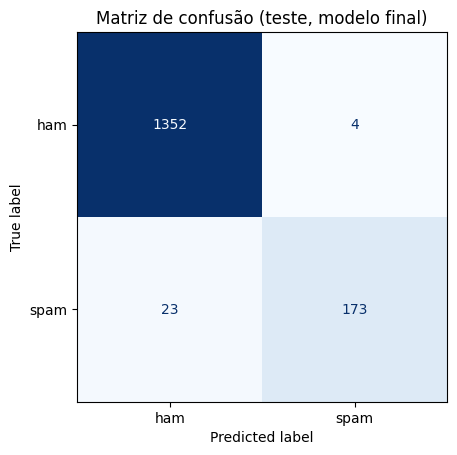

In [35]:
# treinar o modelo final com a melhor configuração, usando todos os dados de treino
best_model = LogisticRegression(max_iter=1000, random_state=42, **best_cfg)
best_model.fit(X_train_sc, y_train)

# avaliar no conjunto de teste
y_pred = best_model.predict(X_test_sc)
y_prob = best_model.predict_proba(X_test_sc)[:, 1]

cm = confusion_matrix(y_test, y_pred)
vn, fp, fn, vp = cm.ravel()
print(pd.DataFrame(cm, index=['real ham', 'real spam'], columns=['previsto ham', 'previsto spam']))
print(f'VN = {vn} | FP = {fp} | FN = {fn} | VP = {vp}')
print()
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisão: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred):.4f}")
print(f"AUC-ROC:  {roc_auc_score(y_test, y_prob):.4f}")

ConfusionMatrixDisplay(cm, display_labels=['ham', 'spam']).plot(cmap='Blues', colorbar=False)
plt.grid(False)
plt.title('Matriz de confusão (teste, modelo final)')
plt.show()

A validação cruzada de 5 folds comparou as configurações de regularização (L1 e L2, com diferentes valores de C) pelo F1 médio e escolheu a impressa em "Melhor configuração". Valores muito pequenos de C regularizam demais e pioram o F1 (underfitting). A configuração escolhida foi treinada com todo o conjunto de treinamento e avaliada no teste. O escore da validação cruzada foi usado para escolher os hiperparâmetros e, por isso, é otimista: a estimativa da performance real do modelo escolhido é a do conjunto de teste, usado apenas no final.

## Tratamento do desbalanceamento das classes com SMOTE (aplicado apenas ao conjunto de treino) e comparação com o modelo anterior

Quando uma classe tem muito menos exemplos que a outra, o modelo tende a favorecer a majoritária. Aqui há poucos spams e o modelo deixa passar alguns (falsos negativos). O **SMOTE** cria amostras **sintéticas** da classe minoritária por interpolação:

$$x_{novo} = x_i + \lambda\,(x_{zi} - x_i), \qquad \lambda \sim U(0,1)$$

Regra fundamental: aplicar o SMOTE **apenas no conjunto de treino**. Reamostrar antes da divisão, ou reamostrar o teste, é uma forma de vazamento de dados (*data leakage*). Isto é diferente da remoção de duplicatas: o SMOTE não procura dados repetidos nem faltantes, ele acrescenta exemplos novos de spam.

In [36]:
# o SMOTE vem da biblioteca imbalanced-learn (instale uma vez, se necessário)
%pip install -q imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [37]:
from imblearn.over_sampling import SMOTE

sm = SMOTE(k_neighbors=5, random_state=42)
X_bal, y_bal = sm.fit_resample(X_train_sc, y_train)    # SOMENTE no treino

print('Treino antes  :', y_train.value_counts().to_dict())
print('Treino depois :', pd.Series(y_bal).value_counts().to_dict())
print('Amostras sintéticas criadas:', len(y_bal) - len(y_train))
print()
print('Teste permanece INTACTO:', y_test.value_counts().to_dict())

Treino antes  : {0: 3162, 1: 457}
Treino depois : {0: 3162, 1: 3162}
Amostras sintéticas criadas: 2705

Teste permanece INTACTO: {0: 1356, 1: 196}


           previsto ham  previsto spam
real ham           1335             21
real spam            17            179
VN = 1335 | FP = 21 | FN = 17 | VP = 179


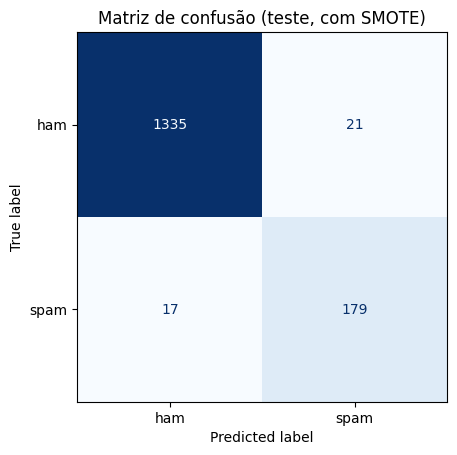

In [38]:
# modelo com a melhor configuração da validação cruzada, treinado com o treino balanceado
model_smote = LogisticRegression(max_iter=1000, random_state=42, **best_cfg)
model_smote.fit(X_bal, y_bal)

# avaliação no teste (que continua com a proporção original)
y_pred_sm = model_smote.predict(X_test_sc)
y_prob_sm = model_smote.predict_proba(X_test_sc)[:, 1]

cm_sm = confusion_matrix(y_test, y_pred_sm)
vn_sm, fp_sm, fn_sm, vp_sm = cm_sm.ravel()
print(pd.DataFrame(cm_sm, index=['real ham', 'real spam'], columns=['previsto ham', 'previsto spam']))
print(f'VN = {vn_sm} | FP = {fp_sm} | FN = {fn_sm} | VP = {vp_sm}')

ConfusionMatrixDisplay(cm_sm, display_labels=['ham', 'spam']).plot(cmap='Blues', colorbar=False)
plt.grid(False)
plt.title('Matriz de confusão (teste, com SMOTE)')
plt.show()

In [39]:
# comparação: modelo sem balanceamento x modelo com SMOTE
comp = pd.DataFrame({
    'Sem balanceamento': [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred), recall_score(y_test, y_pred),
                          f1_score(y_test, y_pred), roc_auc_score(y_test, y_prob), fp, fn],
    'Com SMOTE':         [accuracy_score(y_test, y_pred_sm), precision_score(y_test, y_pred_sm), recall_score(y_test, y_pred_sm),
                          f1_score(y_test, y_pred_sm), roc_auc_score(y_test, y_prob_sm), fp_sm, fn_sm],
}, index=['Acurácia', 'Precisão', 'Revocação', 'F1-score', 'AUC', 'FP (ham bloqueado)', 'FN (spam que passou)'])
print(comp.round(4))

                      Sem balanceamento  Com SMOTE
Acurácia                         0.9826     0.9755
Precisão                         0.9774     0.8950
Revocação                        0.8827     0.9133
F1-score                         0.9276     0.9040
AUC                              0.9876     0.9868
FP (ham bloqueado)               4.0000    21.0000
FN (spam que passou)            23.0000    17.0000


O SMOTE equilibrou o conjunto de treino com spams sintéticos e o teste foi mantido intacto. A tabela mostra o efeito: a **revocação** sobe e os **falsos negativos** diminuem, porque o modelo passa a dar mais peso à classe spam; em troca, a **precisão** cai e os **falsos positivos** aumentam, isto é, mais mensagens desejadas são bloqueadas. O F1 e o AUC não melhoram. Em um filtro de spam o falso positivo é o erro mais caro, por isso o modelo sem balanceamento (com a melhor configuração da validação cruzada) continua sendo a melhor opção aqui; o SMOTE mostra o trade-off entre precisão e revocação.

## Conclusão

A regressão logística, com características simples extraídas do texto (palavras-chave, tamanho, dígitos), separa bem spam de ham e produz um modelo fácil de interpretar: cada coeficiente mostra o efeito de uma característica na probabilidade de spam. As métricas finais estão impressas nas células de avaliação acima. Como as classes são desbalanceadas, a análise se apoia em precisão, revocação, F1 e AUC, e não só na acurácia. A regularização com validação cruzada escolheu a configuração do modelo final.